# Setup

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

## Best ML runs

In [3]:
runs_to_download = []
runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'HybridModel'", experiment_ids=['8'], output_format='list'))
runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'MLP'", experiment_ids=['8'], output_format='list'))
print(len(runs_to_download))

6


In [4]:
import os

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [5]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-05-07 15:27:47,785 - INFO - Downloading artifacts for run 00deaf4fd36048b2bf4570bc1b7fd51c
2026-05-07 15:27:50,855 - INFO - Downloading artifacts for run e5aae344192b4e33b7954d626a5ac580
2026-05-07 15:27:51,925 - INFO - Downloading artifacts for run dafa097c4b5440a09730178436593a22
2026-05-07 15:27:52,974 - INFO - Downloading artifacts for run 601cf36ecde844c6b3be2ae12f22fb0f
2026-05-07 15:27:54,021 - INFO - Downloading artifacts for run e320d7812d394f6fa8a6fcbcaa24330d
2026-05-07 15:27:55,074 - INFO - Downloading artifacts for run fccc96a6c9fe4d579343ed172c29243d


,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.662358,0.662358,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257
1,Node_1,0.0,0.576027,0.576027,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257
2,Node_2,0.0,0.690725,0.690725,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257
3,Node_3,0.0,0.152994,0.152994,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257
4,Node_4,0.0,1.130292,1.130292,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257


In [6]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)

In [7]:
import string
genes_to_letter_map = {}
for i, genes in enumerate(model_name_df['modelled_genes'].unique()):
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
genes_to_letter_map
model_name_df['model_name_long'] = model_name_df['model_name'] + ' ' + model_name_df['modelled_genes'].map(genes_to_letter_map).fillna('')
model_name_df['model_name_long'].nunique()
model_name_df

,run_id,model_name,modelled_genes,model_name_long
0,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
1,e5aae344192b4e33b7954d626a5ac580,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel B
2,dafa097c4b5440a09730178436593a22,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",HybridModel C
3,601cf36ecde844c6b3be2ae12f22fb0f,HybridModel,"['Node_24', 'Node_6', 'Node_28', 'Node_10', 'N...",HybridModel D
4,e320d7812d394f6fa8a6fcbcaa24330d,HybridModel,"['Node_19', 'Node_5', 'Node_15', 'Node_35', 'N...",HybridModel E
5,fccc96a6c9fe4d579343ed172c29243d,MLP,None,MLP


In [8]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,model_name_long
0,Node_0,0.0,0.662358,0.662358,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
1,Node_1,0.0,0.576027,0.576027,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
2,Node_2,0.0,0.690725,0.690725,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
3,Node_3,0.0,0.152994,0.152994,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
4,Node_4,0.0,1.130292,1.130292,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A


Add number of genes

In [9]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,d5a039bbfac647b1af34f1be2e3de257,50


Add noiseless expression values

In [10]:
records = []

assert raw_predictions_df['parent_run_id'].nunique() == 1

for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    # Get submodules from here currently (bit messy)
    submodules = sim_output.network.get_disconnected_modules()
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-05-07 15:28:02,338 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,359 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,363 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,382 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,401 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,434 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,440 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-07 15:28:02,443 - WARNING - Connection p

In [49]:
submodules[0]

{'Node_0',
 'Node_1',
 'Node_11',
 'Node_12',
 'Node_13',
 'Node_14',
 'Node_16',
 'Node_2',
 'Node_20',
 'Node_26',
 'Node_3',
 'Node_30',
 'Node_32',
 'Node_37',
 'Node_39',
 'Node_4',
 'Node_40',
 'Node_41',
 'Node_42',
 'Node_43',
 'Node_45',
 'Node_46',
 'Node_48',
 'Node_7',
 'Node_8',
 'Node_9'}

In [48]:
combos = random.sample([(a, b) for a in submodules[0] for b in submodules[1]], 50)
combos

[('Node_40', 'Node_25'),
 ('Node_3', 'Node_47'),
 ('Node_32', 'Node_27'),
 ('Node_30', 'Node_25'),
 ('Node_14', 'Node_19'),
 ('Node_11', 'Node_24'),
 ('Node_41', 'Node_15'),
 ('Node_46', 'Node_22'),
 ('Node_8', 'Node_6'),
 ('Node_2', 'Node_5'),
 ('Node_3', 'Node_38'),
 ('Node_14', 'Node_36'),
 ('Node_45', 'Node_29'),
 ('Node_39', 'Node_10'),
 ('Node_37', 'Node_21'),
 ('Node_2', 'Node_28'),
 ('Node_12', 'Node_18'),
 ('Node_37', 'Node_24'),
 ('Node_20', 'Node_49'),
 ('Node_40', 'Node_31'),
 ('Node_0', 'Node_24'),
 ('Node_8', 'Node_36'),
 ('Node_42', 'Node_38'),
 ('Node_11', 'Node_5'),
 ('Node_13', 'Node_22'),
 ('Node_3', 'Node_35'),
 ('Node_30', 'Node_17'),
 ('Node_43', 'Node_49'),
 ('Node_11', 'Node_15'),
 ('Node_46', 'Node_44'),
 ('Node_14', 'Node_35'),
 ('Node_20', 'Node_31'),
 ('Node_2', 'Node_29'),
 ('Node_32', 'Node_18'),
 ('Node_11', 'Node_29'),
 ('Node_46', 'Node_33'),
 ('Node_48', 'Node_34'),
 ('Node_48', 'Node_33'),
 ('Node_20', 'Node_27'),
 ('Node_48', 'Node_31'),
 ('Node_12',

In [51]:
len(submodules[0].union(submodules[1]))

50

In [53]:
combos

[('Node_40', 'Node_25'),
 ('Node_3', 'Node_47'),
 ('Node_32', 'Node_27'),
 ('Node_30', 'Node_25'),
 ('Node_14', 'Node_19'),
 ('Node_11', 'Node_24'),
 ('Node_41', 'Node_15'),
 ('Node_46', 'Node_22'),
 ('Node_8', 'Node_6'),
 ('Node_2', 'Node_5'),
 ('Node_3', 'Node_38'),
 ('Node_14', 'Node_36'),
 ('Node_45', 'Node_29'),
 ('Node_39', 'Node_10'),
 ('Node_37', 'Node_21'),
 ('Node_2', 'Node_28'),
 ('Node_12', 'Node_18'),
 ('Node_37', 'Node_24'),
 ('Node_20', 'Node_49'),
 ('Node_40', 'Node_31'),
 ('Node_0', 'Node_24'),
 ('Node_8', 'Node_36'),
 ('Node_42', 'Node_38'),
 ('Node_11', 'Node_5'),
 ('Node_13', 'Node_22'),
 ('Node_3', 'Node_35'),
 ('Node_30', 'Node_17'),
 ('Node_43', 'Node_49'),
 ('Node_11', 'Node_15'),
 ('Node_46', 'Node_44'),
 ('Node_14', 'Node_35'),
 ('Node_20', 'Node_31'),
 ('Node_2', 'Node_29'),
 ('Node_32', 'Node_18'),
 ('Node_11', 'Node_29'),
 ('Node_46', 'Node_33'),
 ('Node_48', 'Node_34'),
 ('Node_48', 'Node_33'),
 ('Node_20', 'Node_27'),
 ('Node_48', 'Node_31'),
 ('Node_12',

In [ ]:
all_nodes = [f"Node_{i}" for i in range(50)]
rows = []
for a, b in combos:
    row = {node: 0 if node in (a, b) else 1 for node in all_nodes}
    rows.append(row)

df = pd.DataFrame(rows, columns=all_nodes)
df

df.to_csv("my_network_dualknockouts_perturbations.tsv", sep="\t", index=False)

,Node_0,Node_1,Node_2,Node_3,Node_4,Node_5,Node_6,Node_7,Node_8,Node_9,...,Node_40,Node_41,Node_42,Node_43,Node_44,Node_45,Node_46,Node_47,Node_48,Node_49
0,1,1,1,1,1,1,1,1,1,1,...,0,1,1,1,1,1,1,1,1,1
1,1,1,1,0,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
2,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
3,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
4,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
5,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,...,1,0,1,1,1,1,1,1,1,1
7,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,0,1,1,1
8,1,1,1,1,1,1,0,1,0,1,...,1,1,1,1,1,1,1,1,1,1
9,1,1,0,1,1,0,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [11]:
nr_genes_df.head()

,parent_run_id,nr_genes
0,d5a039bbfac647b1af34f1be2e3de257,50


In [12]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,model_name_long
0,Node_0,0.0,0.662358,0.662358,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
1,Node_1,0.0,0.576027,0.576027,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
2,Node_2,0.0,0.690725,0.690725,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
3,Node_3,0.0,0.152994,0.152994,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A
4,Node_4,0.0,1.130292,1.130292,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,d5a039bbfac647b1af34f1be2e3de257,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel A


In [13]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.519937,KO: Node_0. Env: None,d5a039bbfac647b1af34f1be2e3de257
1,Node_1,0.0,0.427606,KO: Node_0. Env: None,d5a039bbfac647b1af34f1be2e3de257
2,Node_2,0.0,0.591159,KO: Node_0. Env: None,d5a039bbfac647b1af34f1be2e3de257
3,Node_3,0.0,0.328399,KO: Node_0. Env: None,d5a039bbfac647b1af34f1be2e3de257
4,Node_4,0.0,0.925160,KO: Node_0. Env: None,d5a039bbfac647b1af34f1be2e3de257


Merging

In [14]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [15]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes', 'model_name_long']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes,model_name_long
0,Node_0,0.0,0.662358,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",0.519937,50,HybridModel A
1,Node_1,0.0,0.576027,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",0.427606,50,HybridModel A
2,Node_2,0.0,0.690725,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",0.591159,50,HybridModel A
3,Node_3,0.0,0.152994,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",0.328399,50,HybridModel A
4,Node_4,0.0,1.130292,KO: Node_9. Env: None,00deaf4fd36048b2bf4570bc1b7fd51c,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",0.925160,50,HybridModel A
...,...,...,...,...,...,...,...,...,...,...
629995,Node_45,1.0,0.638702,KO: Node_1. Env: None,fccc96a6c9fe4d579343ed172c29243d,MLP,None,0.491875,50,MLP
629996,Node_46,1.0,0.908256,KO: Node_1. Env: None,fccc96a6c9fe4d579343ed172c29243d,MLP,None,0.917063,50,MLP
629997,Node_47,1.0,0.889594,KO: Node_1. Env: None,fccc96a6c9fe4d579343ed172c29243d,MLP,None,0.815632,50,MLP
629998,Node_48,1.0,0.213279,KO: Node_1. Env: None,fccc96a6c9fe4d579343ed172c29243d,MLP,None,0.193101,50,MLP


In [16]:
outcome['model_name'].unique()

array(['HybridModel', 'MLP'], dtype=object)

In [17]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [18]:
stdev_df = outcome.groupby(['gene', 'condition', 'nr_genes'])['noiseless_ground_truth'].std().reset_index().rename(
    columns={'noiseless_ground_truth': 'gene_expression_stdev'})
stdev_df.head()

,gene,condition,nr_genes,gene_expression_stdev
0,Node_0,"KO: Node_0, Node_16. Env: None",50,0.042623
1,Node_0,"KO: Node_0, Node_2. Env: None",50,0.043827
2,Node_0,"KO: Node_0, Node_9. Env: None",50,0.041353
3,Node_0,KO: Node_0. Env: None,50,0.111196
4,Node_0,"KO: Node_1, Node_13. Env: None",50,0.029782


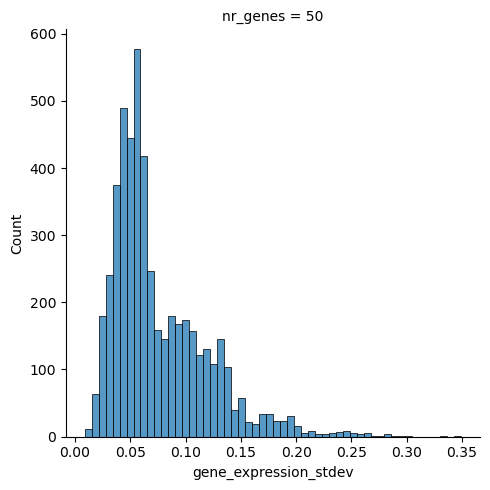

In [19]:
sns.displot(data =stdev_df, col='nr_genes', x='gene_expression_stdev')

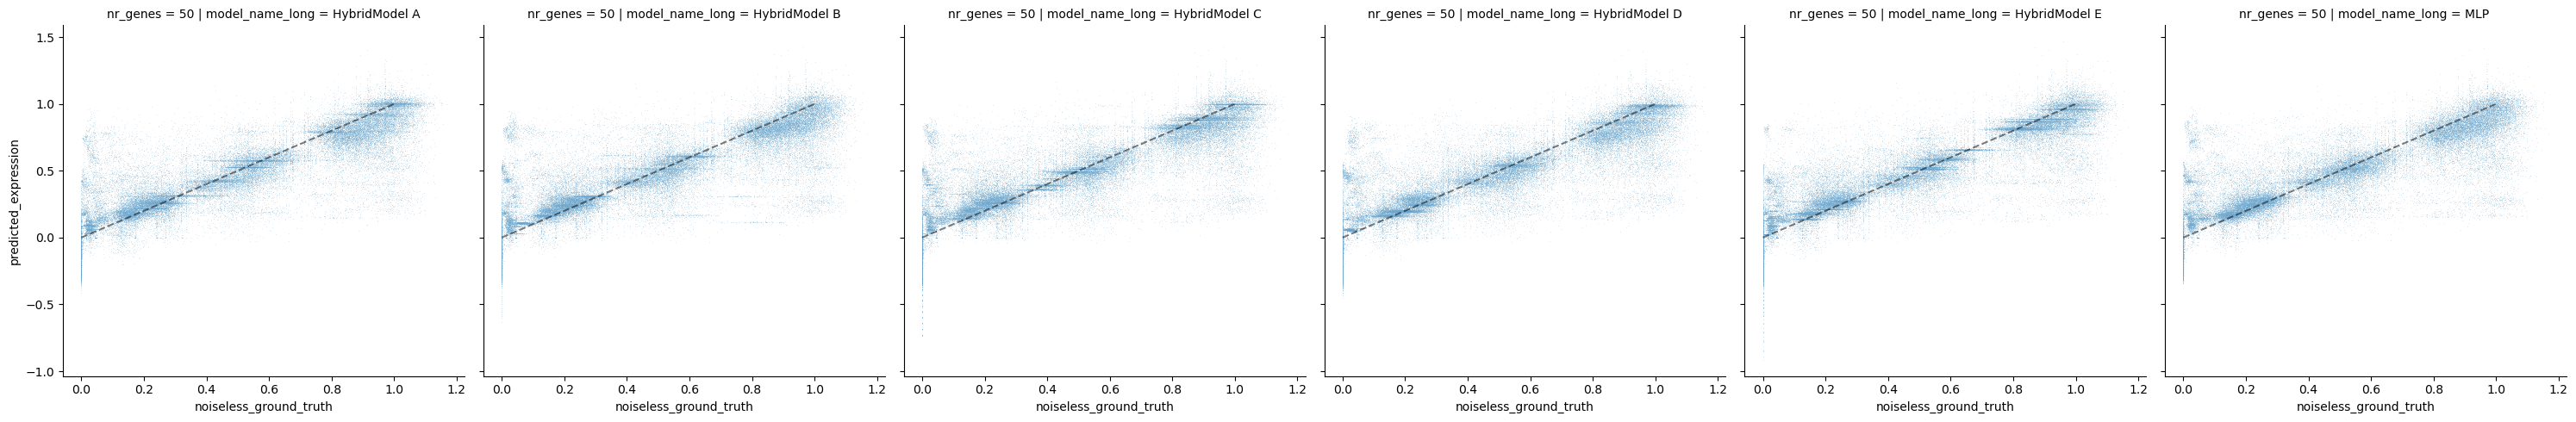

In [20]:
g = sns.relplot(data=double_ko_df, kind='scatter', x='noiseless_ground_truth', y='predicted_expression', col='model_name_long', row='nr_genes', s=2, alpha=.2, marker='.')

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

# Plotting for double KO

In [21]:
from copy import deepcopy
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [45]:
submodules[1]

{'Node_10',
 'Node_15',
 'Node_17',
 'Node_18',
 'Node_19',
 'Node_21',
 'Node_22',
 'Node_23',
 'Node_24',
 'Node_25',
 'Node_27',
 'Node_28',
 'Node_29',
 'Node_31',
 'Node_33',
 'Node_34',
 'Node_35',
 'Node_36',
 'Node_38',
 'Node_44',
 'Node_47',
 'Node_49',
 'Node_5',
 'Node_6'}

In [46]:
list(paired['condition'].unique())

['KO: Node_0, Node_16. Env: None',
 'KO: Node_0, Node_2. Env: None',
 'KO: Node_0, Node_9. Env: None',
 'KO: Node_1, Node_13. Env: None',
 'KO: Node_1, Node_20. Env: None',
 'KO: Node_1, Node_26. Env: None',
 'KO: Node_1, Node_3. Env: None',
 'KO: Node_1, Node_30. Env: None',
 'KO: Node_1, Node_32. Env: None',
 'KO: Node_1, Node_4. Env: None',
 'KO: Node_1, Node_40. Env: None',
 'KO: Node_1, Node_8. Env: None',
 'KO: Node_13, Node_20. Env: None',
 'KO: Node_15, Node_19. Env: None',
 'KO: Node_15, Node_21. Env: None',
 'KO: Node_15, Node_34. Env: None',
 'KO: Node_15, Node_35. Env: None',
 'KO: Node_16, Node_20. Env: None',
 'KO: Node_17, Node_18. Env: None',
 'KO: Node_17, Node_24. Env: None',
 'KO: Node_17, Node_31. Env: None',
 'KO: Node_18, Node_31. Env: None',
 'KO: Node_19, Node_21. Env: None',
 'KO: Node_19, Node_34. Env: None',
 'KO: Node_19, Node_35. Env: None',
 'KO: Node_2, Node_12. Env: None',
 'KO: Node_2, Node_14. Env: None',
 'KO: Node_2, Node_16. Env: None',
 'KO: Node_2

In [ ]:
def ko_in_same_submodule(df, disconnected_modules):
    df = deepcopy(df)
    for condition in df['condition'].unique():
        kos = re.findall(r"Node_\d+", condition)
        module_indices = []
        for ko in kos:
            module_index = [i for i, module in enumerate(disconnected_modules) if ko in module]
            module_indices.extend(module_index)
        if len(set(module_indices)) == 1:
            df.loc[df['condition'] == condition, 'ko_in_same_submodule'] = True
        else:
            df.loc[df['condition'] == condition, 'ko_in_same_submodule'] = False
    return df


In [23]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_genes'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'nr_genes', 'MSE']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'nr_genes', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_genes'])
paired = annotate_kos_in_df(paired)


In [41]:
new_df = ko_in_same_submodule(paired, submodules)

In [37]:
new_df['ko_in_same_submodule'].value_counts()

ko_in_same_submodule
True    12500
Name: count, dtype: int64

In [36]:
new_df[['ko_in_mm', 'gene_in_mm', 'ko_in_same_submodule']].drop_duplicates()

,ko_in_mm,gene_in_mm,ko_in_same_submodule
0,partially,False,True
1,none,False,True
3,fully,False,True
50,partially,True,True
51,none,True,True
53,fully,True,True


In [ ]:
paired.head()

In [ ]:
mse_df.head()

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',
                  alpha=.75, s=20, col_order=natsorted(paired['nr_genes'].unique()),  #height=2, aspect=1,
                    facet_kws={'margin_titles': True}, palette=palette)
# g.figure.set_size_inches(9, 3) 
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
for text in g._margin_titles_texts:
    text.set_visible(False)
# g.savefig("scatter_mlp_hybrid_lin_no_hue.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
mse_df

In [ ]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g= sns.catplot(data=paired[paired['gene_in_mm'] == True], kind='boxen',x='nr_genes', y='hybrid_mse',  height=2.5, aspect=1,
            log_scale=True, order=natsorted(paired['nr_genes'].unique()), col='ko_in_mm', row='gene_in_mm', color=sns.color_palette()[1],
            margin_titles= True)

# g.savefig("hybrid_mse_gene_in_mm_but_ko_in_or_out.pdf", dpi=600, bbox_inches='tight')

In [ ]:
paired.shape

In [ ]:
print(paired.head())

In [ ]:
print(stdev_df)

In [ ]:
stdev_df.shape

In [ ]:
paired_with_variation_per_gene = pd.merge(paired, stdev_df, 'left', on=['gene', 'condition', 'nr_genes'])
paired_with_variation_per_gene.shape

In [ ]:
paired_with_variation_per_gene.head()

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',
                  alpha=.75, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), 
                    facet_kws={'margin_titles': True}, palette=palette)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
# ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    # ax.plot([global_min, global_max], [global_min, global_max], 'k--', lw=0.8, zorder=0)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)


for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

for text in g._margin_titles_texts:
    text.set_visible(False)

# g.savefig("scatter_mlp_hybrid_log_no_hue.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.8, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), # height=2, aspect=1,
                    facet_kws={'margin_titles': True},  palette='magma',)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

# g.savefig("scatter_mlp_hybrid_log_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.75, s=20, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()),  palette='magma',
                    facet_kws={'margin_titles': True})
# g.figure.set_size_inches(9, 3) 
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

# g.savefig("scatter_mlp_hybrid_lin_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == True]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()))
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)

# g.savefig("scatter_mlp_hybrid_only_genes_in_mm_lin_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == False]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=['none', 'partially', 'fully'] )
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

In [ ]:
paired_with_variation_per_gene.head()

In [ ]:
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='ko_in_mm', row='gene_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=['none', 'partially', 'fully'] )
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
# g.savefig("scatter_mlp_hybrid_only_genes_in_mm_log_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )